# Task 2: Real Estate Housing Price Prediction (OLS, Ridge & Lasso Regression)
**Datheon Machine Learning & Data Science Internship**

### Objective & Problem Statement
Predict `median_house_value` across California census block groups using the **California Housing Dataset** (`housing.csv`, $n = 20,640$). This pipeline implements:
1. **Data Exploration & Missing Value Imputation:** Median imputation (`SimpleImputer(strategy='median')`) for missing `total_bedrooms` records.
2. **Feature Engineering & Multicollinearity Analysis:** Creation of domain ratio and interaction features (`rooms_per_household`, `bedrooms_per_room`, `population_per_household`, `income_x_rooms`) and Pearson correlation heatmap visualization.
3. **Categorical Encoding & Feature Standardization:** One-hot encoding of `ocean_proximity` and `StandardScaler` normalization fit strictly on the 80% training partition.
4. **Hyperparameter Tuning (`GridSearchCV`) & Model Benchmarking:** 5-fold cross-validation across $\alpha \in [0.01, 0.1, 1.0, 10.0, 50.0, 100.0, 250.0]$ comparing **Ordinary Least Squares (`LinearRegression`)**, **Ridge (`L2`)**, and **Lasso (`L1`)** across **RMSE**, **MAE**, and **$R^2$** scores.
5. **Diagnostic Visualizations:** Predicted vs. Actual scatter plots, residual error distribution curves (KDE), homoscedasticity checks, and L1/L2 coefficient shrinkage profiles.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

# 1. Load the California Housing Dataset
df = pd.read_csv("housing.csv")
print(f"Dataset Shape: {df.shape[0]:,} rows × {df.shape[1]} columns\n")
print("Missing Values per Column:")
print(df.isnull().sum())
print("\nOcean Proximity Category Counts:")
print(df["ocean_proximity"].value_counts())
df.head()


Dataset Shape: 20,640 rows × 10 columns

Missing Values per Column:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Ocean Proximity Category Counts:
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


### Step 2: Missing Value Imputation, Feature Engineering & Correlation Heatmap
The raw count attributes (`total_rooms`, `total_bedrooms`, `population`, `households`) scale directly with census block size and exhibit strong multicollinearity ($r > 0.85$). We impute the 207 missing `total_bedrooms` values using the median and engineer normalized household/room ratios plus a non-linear income-room interaction (`income_x_rooms`).


Median Imputation Value for 'total_bedrooms': 452.0 bedrooms
Remaining Null Values After Imputation: 0



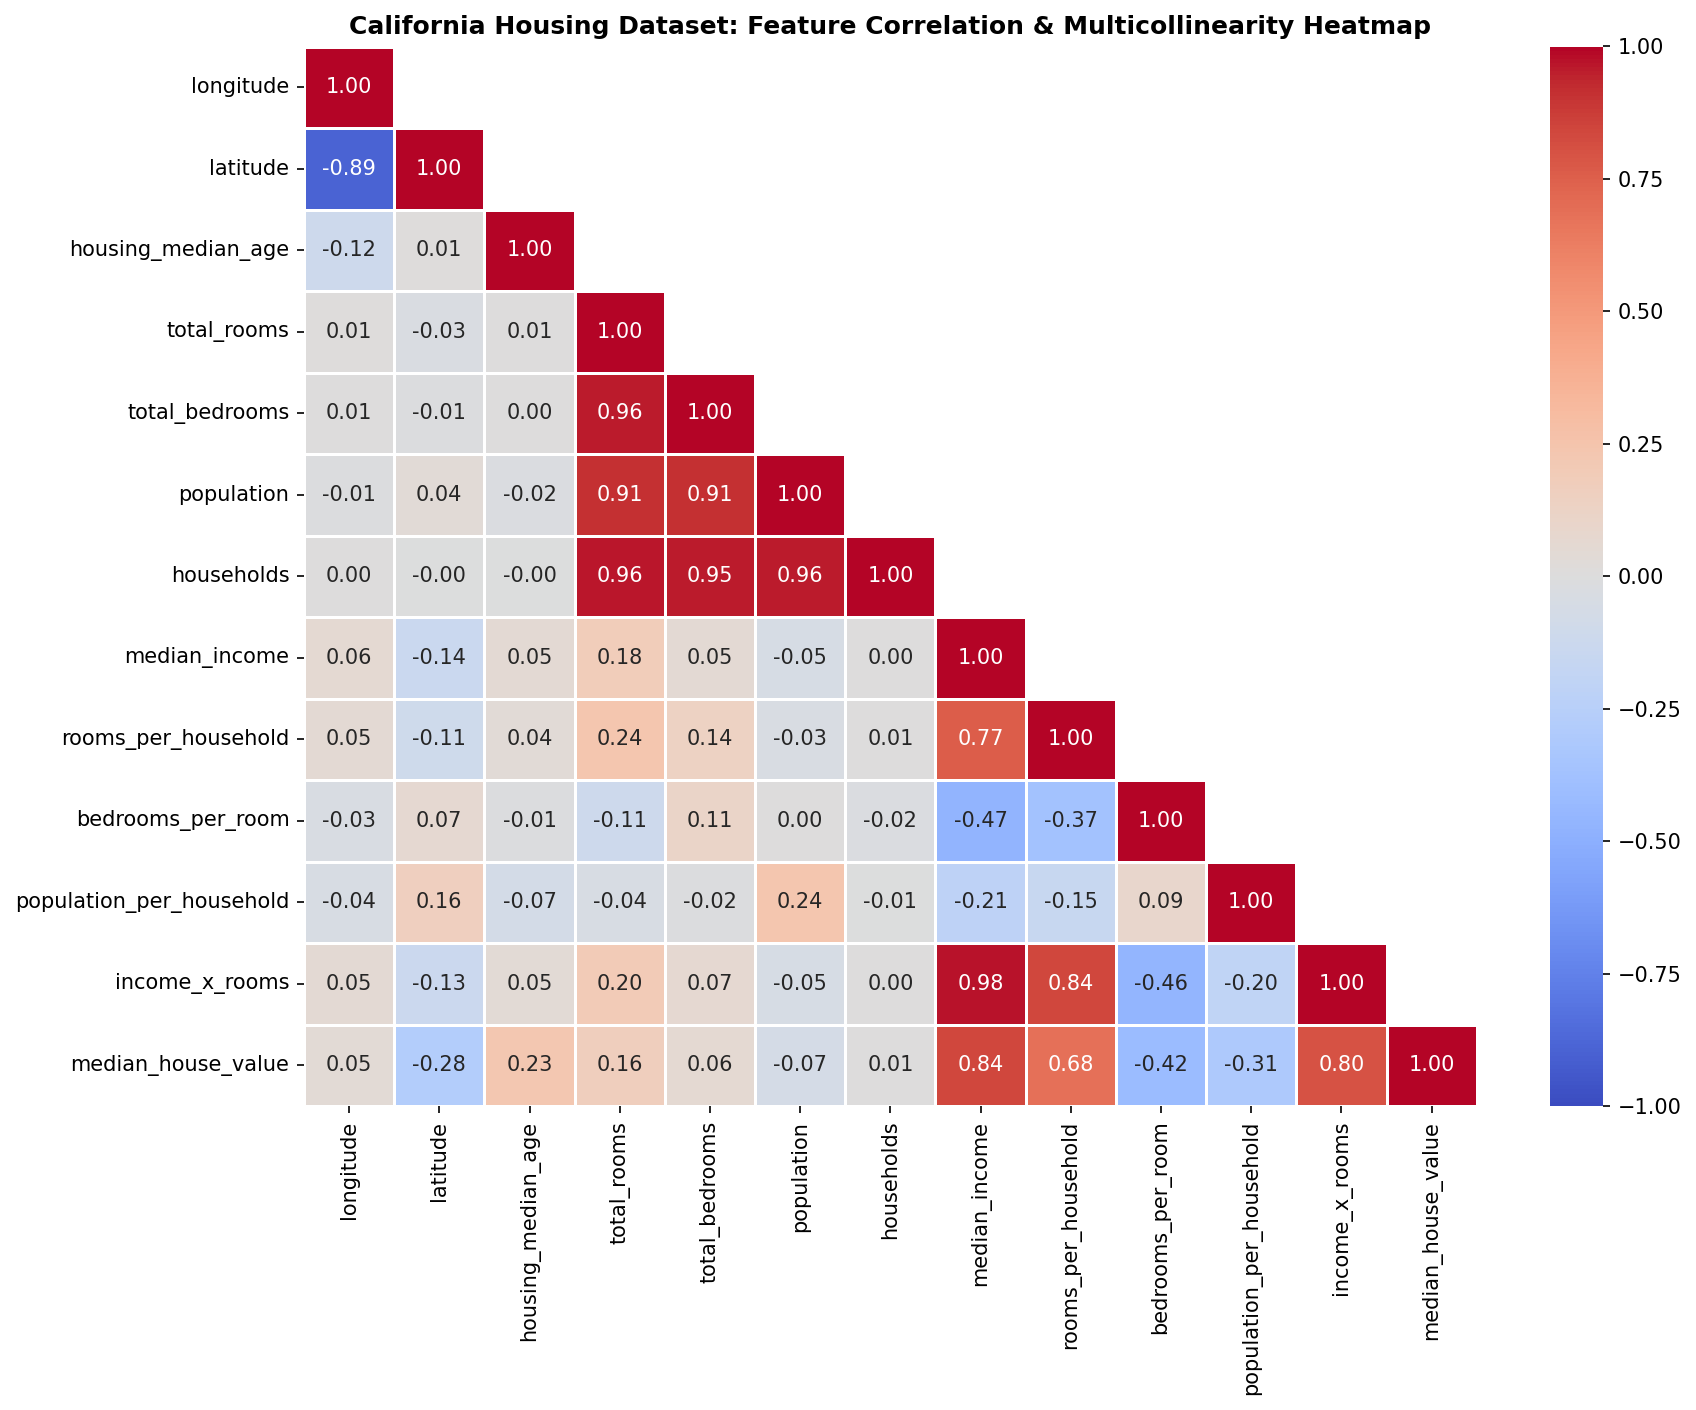

In [3]:
# 2a. Impute missing values in 'total_bedrooms' using median strategy
imputer = SimpleImputer(strategy="median")
df_imputed = df.copy()
df_imputed[["total_bedrooms"]] = imputer.fit_transform(df[["total_bedrooms"]])
print(f"Median Imputation Value for 'total_bedrooms': {imputer.statistics_[0]:.1f} bedrooms")
print(f"Remaining Null Values After Imputation: {df_imputed.isnull().sum().sum()}\n")

# 2b. Engineer domain ratio and interaction features
df_imputed["rooms_per_household"] = df_imputed["total_rooms"] / df_imputed["households"]
df_imputed["bedrooms_per_room"] = df_imputed["total_bedrooms"] / df_imputed["total_rooms"]
df_imputed["population_per_household"] = df_imputed["population"] / df_imputed["households"]
df_imputed["income_x_rooms"] = df_imputed["median_income"] * df_imputed["rooms_per_household"]

# 2c. Compute and plot Correlation Heatmap
numeric_cols = [
    "longitude", "latitude", "housing_median_age",
    "total_rooms", "total_bedrooms", "population", "households",
    "median_income", "rooms_per_household", "bedrooms_per_room",
    "population_per_household", "income_x_rooms", "median_house_value"
]
corr_matrix = df_imputed[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(12, 9.5), dpi=150)
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
    vmin=-1.0, vmax=1.0, center=0.0, linewidths=0.6, ax=ax
)
ax.set_title("California Housing Dataset: Feature Correlation & Multicollinearity Heatmap", fontweight="bold")
plt.tight_layout()
plt.savefig("housing_correlation_heatmap.png", dpi=200)
plt.show()


### Step 3: Categorical Encoding, Train/Test Split (80/20) & Standardization
We one-hot encode `ocean_proximity` (`drop_first=True` to avoid the dummy variable trap), partition the dataset into an 80% training set ($16,512$ rows) and 20% test set ($4,128$ rows), and standardize continuous predictors via `StandardScaler()` fit strictly on the training set so that L1 and L2 penalties penalize all features on a uniform scale.


In [4]:
# 3a. One-Hot Encode 'ocean_proximity'
df_encoded = pd.get_dummies(df_imputed, columns=["ocean_proximity"], drop_first=True, dtype=float)

feature_cols = [c for c in df_encoded.columns if c != "median_house_value"]
continuous_cols = [
    "longitude", "latitude", "housing_median_age",
    "total_rooms", "total_bedrooms", "population", "households",
    "median_income", "rooms_per_household", "bedrooms_per_room",
    "population_per_household", "income_x_rooms"
]
categorical_dummy_cols = [c for c in feature_cols if c not in continuous_cols]

X = df_encoded[feature_cols].copy()
y = df_encoded["median_house_value"].values

# 3b. 80/20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# 3c. Standardize Continuous Variables using StandardScaler
scaler = StandardScaler()
X_train[continuous_cols] = scaler.fit_transform(X_train[continuous_cols])
X_test[continuous_cols] = scaler.transform(X_test[continuous_cols])

print(f"Encoded Feature Matrix Shape: {X.shape}")
print(f"Training Set: {X_train.shape[0]:,} samples | Hold-Out Test Set: {X_test.shape[0]:,} samples")
print(f"Standardized Continuous Features ({len(continuous_cols)}): {continuous_cols}")
print(f"One-Hot Encoded Dummies ({len(categorical_dummy_cols)}): {categorical_dummy_cols}")


Encoded Feature Matrix Shape: (20640, 16)
Training Set: 16,512 samples | Hold-Out Test Set: 4,128 samples
Standardized Continuous Features (12): ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_x_rooms']
One-Hot Encoded Dummies (4): ['ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']


### Step 4: Model Training & Hyperparameter Tuning with `GridSearchCV`
We fit **Ordinary Least Squares (`LinearRegression`)** as our unregularized baseline, and tune **Ridge (`L2`)** and **Lasso (`L1`)** across $\alpha \in [0.01, 0.1, 1.0, 10.0, 50.0, 100.0, 250.0]$ using 5-fold cross-validation (`GridSearchCV`).


In [5]:
# 4a. Baseline Ordinary Least Squares (OLS)
ols_model = LinearRegression()
ols_model.fit(X_train, y_train)
y_pred_ols = ols_model.predict(X_test)

# 4b. Hyperparameter Grid & 5-Fold Cross-Validation for Ridge (L2) and Lasso (L1)
param_grid = {"alpha": [0.01, 0.1, 1.0, 10.0, 50.0, 100.0, 250.0]}
cv = KFold(n_splits=5, shuffle=True, random_state=42)

ridge_grid = GridSearchCV(
    Ridge(random_state=42),
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)
ridge_grid.fit(X_train, y_train)
best_ridge = ridge_grid.best_estimator_
y_pred_ridge = best_ridge.predict(X_test)

lasso_grid = GridSearchCV(
    Lasso(max_iter=5000, random_state=42),
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)
lasso_grid.fit(X_train, y_train)
best_lasso = lasso_grid.best_estimator_
y_pred_lasso = best_lasso.predict(X_test)

# 4c. Evaluate RMSE, MAE, and R^2 on the Hold-Out Test Set
for name, preds in [
    ("Ordinary Least Squares (OLS)", y_pred_ols),
    (f"Ridge Regression (L2, α={ridge_grid.best_params_['alpha']})", y_pred_ridge),
    (f"Lasso Regression (L1, α={lasso_grid.best_params_['alpha']})", y_pred_lasso),
]:
    rmse = root_mean_squared_error(y_test, preds)
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)
    print(f"{name:<32} | Test RMSE: ${rmse:>10,.2f} | Test MAE: ${mae:>10,.2f} | Test R²: {r2:.4f}")


Ordinary Least Squares (OLS)     | Test RMSE: $ 38,705.64 | Test MAE: $ 30,658.10 | Test R²: 0.9036
Ridge Regression (L2, α=0.1)     | Test RMSE: $ 38,705.97 | Test MAE: $ 30,658.05 | Test R²: 0.9036
Lasso Regression (L1, α=0.01)    | Test RMSE: $ 38,705.64 | Test MAE: $ 30,658.09 | Test R²: 0.9036


### Step 5: Predicted vs. Actual Values & Residual Error Analysis
We visualize the hold-out test set predictions against actual house values ($y = x$ reference line), inspect the residual error distribution curves (KDE) for normality and zero-mean centering, verify homoscedasticity, and compare standardized feature weights across OLS, Ridge, and sparse Lasso.


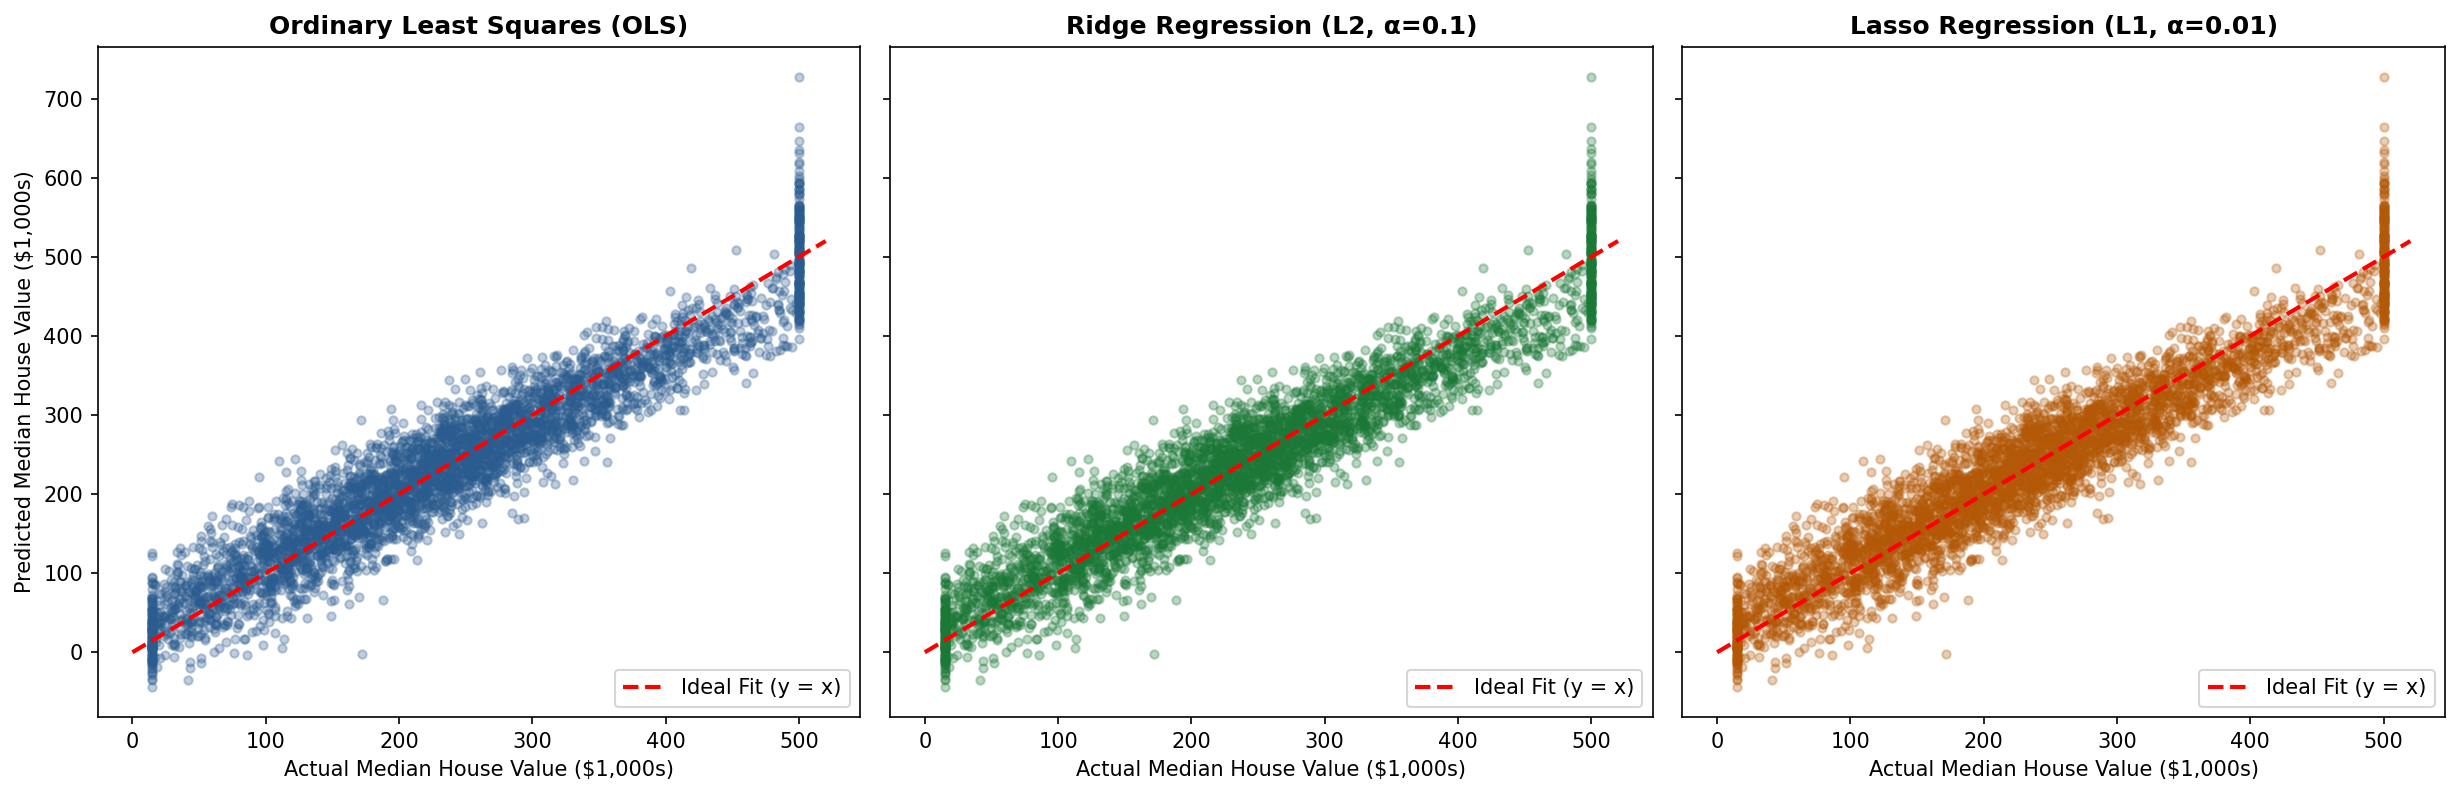

In [6]:
# 5a. Plot Predicted vs. Actual Values for OLS, Ridge, and Lasso
fig, axes = plt.subplots(1, 3, figsize=(16.5, 5.4), dpi=150, sharey=True)
models_plot = [
    ("Ordinary Least Squares (OLS)", y_pred_ols, "#2b5c8f"),
    (f"Ridge Regression (L2, α={ridge_grid.best_params_['alpha']})", y_pred_ridge, "#1b7837"),
    (f"Lasso Regression (L1, α={lasso_grid.best_params_['alpha']})", y_pred_lasso, "#b35806"),
]

for ax, (title, preds, color) in zip(axes, models_plot):
    ax.scatter(y_test / 1000.0, preds / 1000.0, alpha=0.3, s=16, color=color)
    ax.plot([0, 520], [0, 520], "r--", lw=2.0, label="Ideal Fit (y = x)")
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Actual Median House Value ($1,000s)")
    if ax == axes[0]:
        ax.set_ylabel("Predicted Median House Value ($1,000s)")
    ax.legend(loc="lower right")

plt.tight_layout()
plt.savefig("housing_predicted_vs_actual.png", dpi=200)
plt.show()


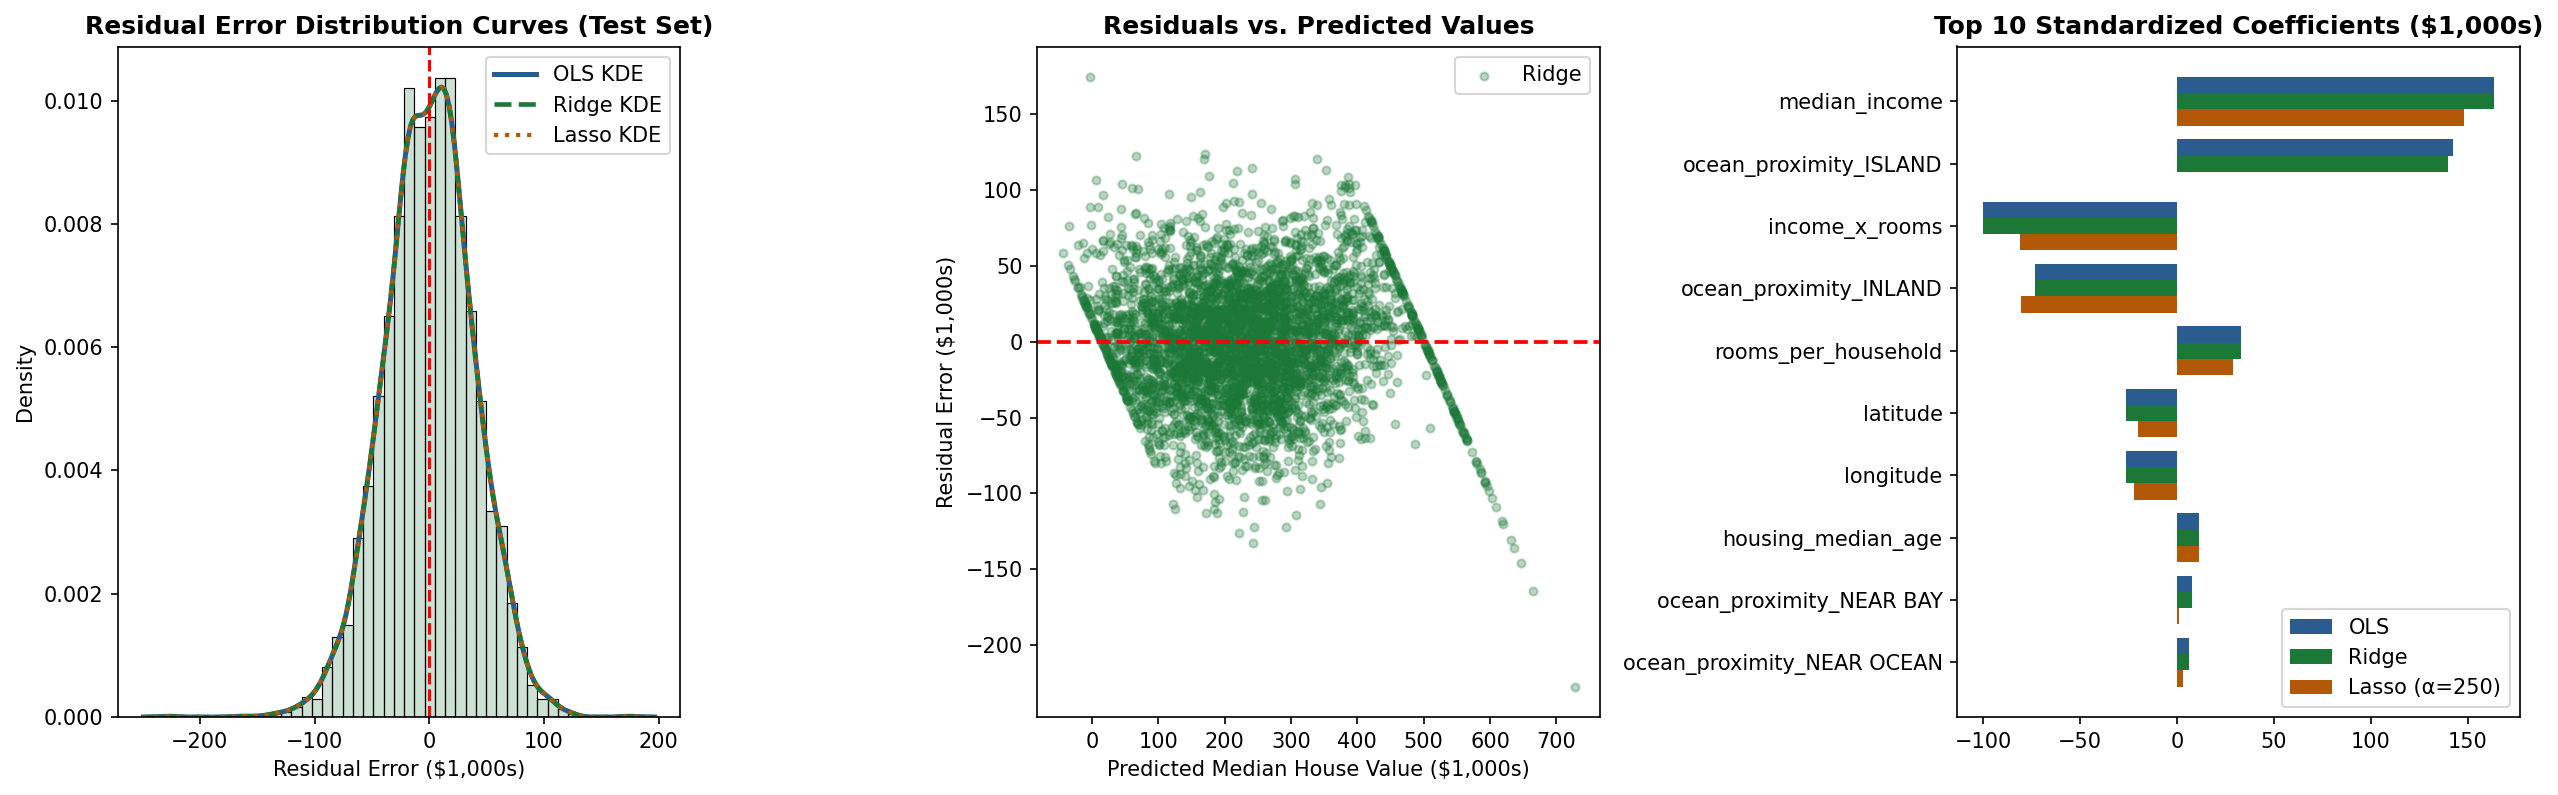

In [7]:
# 5b. Plot Residual Distribution Curves, Homoscedasticity & Regularization Coefficients
res_ols = (y_test - y_pred_ols) / 1000.0
res_ridge = (y_test - y_pred_ridge) / 1000.0
res_lasso = (y_test - y_pred_lasso) / 1000.0

fig, axes = plt.subplots(1, 3, figsize=(17, 5.4), dpi=150)

# Panel 1: Residual Distribution KDE Curves
sns.histplot(res_ridge, bins=45, stat="density", color="#1b7837", alpha=0.22, ax=axes[0])
sns.kdeplot(res_ols, color="#2b5c8f", lw=2.4, ax=axes[0], label="OLS KDE")
sns.kdeplot(res_ridge, color="#1b7837", lw=2.2, linestyle="--", ax=axes[0], label="Ridge KDE")
sns.kdeplot(res_lasso, color="#b35806", lw=2.0, linestyle=":", ax=axes[0], label="Lasso KDE")
axes[0].axvline(0.0, color="red", linestyle="--", lw=1.5)
axes[0].set_title("Residual Error Distribution Curves (Test Set)", fontweight="bold")
axes[0].set_xlabel("Residual Error ($1,000s)")
axes[0].legend()

# Panel 2: Residuals vs. Predicted Values
axes[1].scatter(y_pred_ridge / 1000.0, res_ridge, alpha=0.3, s=15, color="#1b7837", label="Ridge")
axes[1].axhline(0.0, color="red", linestyle="--", lw=1.8)
axes[1].set_title("Residuals vs. Predicted Values", fontweight="bold")
axes[1].set_xlabel("Predicted Median House Value ($1,000s)")
axes[1].set_ylabel("Residual Error ($1,000s)")
axes[1].legend()

# Panel 3: Top Standardized Feature Coefficients
lasso_sparse = Lasso(alpha=250.0, max_iter=5000, random_state=42).fit(X_train, y_train)
top_idx = np.argsort(np.abs(ols_model.coef_))[-10:]
y_pos = np.arange(len(top_idx))
axes[2].barh(y_pos + 0.26, ols_model.coef_[top_idx] / 1000.0, height=0.26, color="#2b5c8f", label="OLS")
axes[2].barh(y_pos, best_ridge.coef_[top_idx] / 1000.0, height=0.26, color="#1b7837", label="Ridge")
axes[2].barh(y_pos - 0.26, lasso_sparse.coef_[top_idx] / 1000.0, height=0.26, color="#b35806", label="Lasso (α=250)")
axes[2].set_yticks(y_pos)
axes[2].set_yticklabels([feature_cols[i] for i in top_idx])
axes[2].set_title("Top 10 Standardized Coefficients ($1,000s)", fontweight="bold")
axes[2].legend()

plt.tight_layout()
plt.savefig("housing_residuals_analysis.png", dpi=200)
plt.show()
